In [2]:
from datasets import load_dataset

print("Loading training dataset...")

train = load_dataset(
    "Multimodal-Fatima/CUB_train",
    split="train"
)

print("Loading test dataset...")

test = load_dataset(
    "Multimodal-Fatima/CUB_test",
    split="test"
)

print("Datasets loaded successfully!")

Loading training dataset...


README.md:   0%|          | 0.00/7.16k [00:00<?, ?B/s]

c:\Users\maria\OneDrive\Desktop\deep learning\From-Pixels-to-Language\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\maria\.cache\huggingface\hub\datasets--Multimodal-Fatima--CUB_train. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\maria\OneDrive\Desktop\deep learning\From-Pixels-to-La

data/train-00000-of-00002-5e7d350dbc117c(…): reconstructing file:   0%|          |  0.00B /  287MB            

data/train-00000-of-00002-5e7d350dbc117c(…): downloading bytes:           |  0.00B            

...

data/test-00000-of-00002-32b23bf2f7b849a(…): downloading bytes:           |  0.00B            

data/test-00001-of-00002-3cd446126954ca1(…): reconstructing file:   0%|          |  0.00B /  286MB            

data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]

Datasets loaded successfully!


In [3]:
print("Training examples:", len(train))
print("Test examples:", len(test))

print("\nAvailable fields:")
print(train.column_names)

Training examples: 5994
Test examples: 5794

Available fields:
['image', 'description', 'label', 'file_name', 'id']


In [4]:
example = train[0]

print("Label:", example["label"])
print("Caption text:")
print(example["description"])

print("\nImage type:", type(example["image"]))
print("Image size:", example["image"].size)

Label: 0
Caption text:
this bird is brown with a lighter brown crest.
aquatic large bird with long hooked bill, white face, and brown body.
bird has brown body feathers, brown breast feathers, and brown beak
this bird has a white superciliary and brown all around its body with a long bill
this is a brown bird with a white face and a long downward pointing beak.
this bird is brown with white and has a long, pointy beak.
brown duck playing on the lake making a poodle
this bird has wings that are brown and has a long bill
this bird has long brown bill, with a brown body.
this is a medium sized brown bird, with a long pointed bill.


Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (500, 301)


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert the labels into a pandas Series
labels = pd.Series([example["label"] for example in train])

# Count the number of examples in each class
class_counts = labels.value_counts().sort_index()

print("Number of classes:", class_counts.size)
print("\nImages per class:")
print(class_counts)

print("\nMinimum images in a class:", class_counts.min())
print("Maximum images in a class:", class_counts.max())
print("Average images per class:", class_counts.mean())

Number of classes: 200

Images per class:
0      30
1      30
2      30
3      30
4      30
       ..
195    29
196    30
197    30
198    30
199    30
Name: count, Length: 200, dtype: int64

Minimum images in a class: 29
Maximum images in a class: 30
Average images per class: 29.97


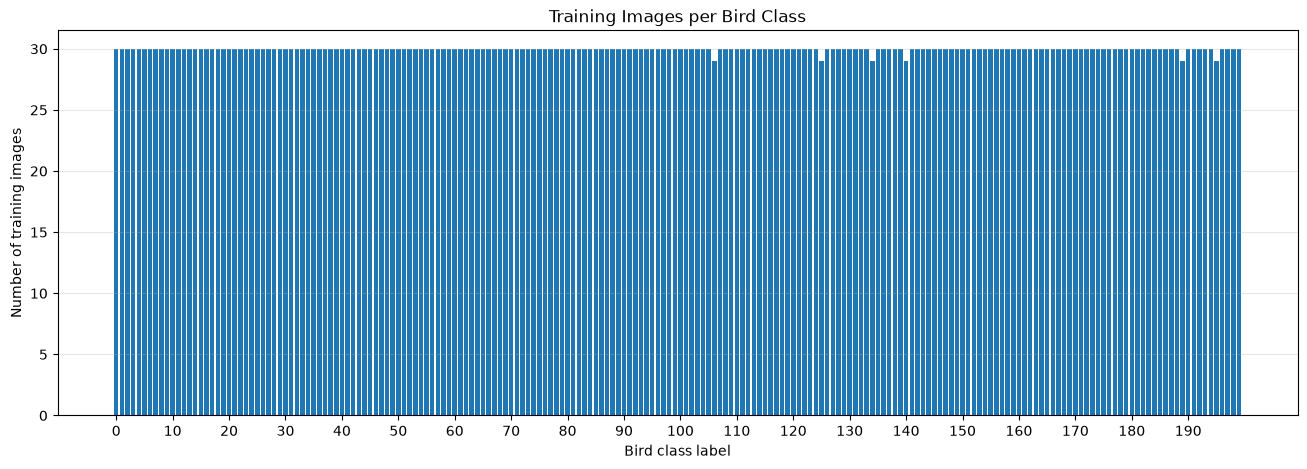

In [6]:
plt.figure(figsize=(16, 5))

plt.bar(class_counts.index, class_counts.values)

plt.xlabel("Bird class label")
plt.ylabel("Number of training images")
plt.title("Training Images per Bird Class")
plt.xticks(range(0, 200, 10))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [7]:
from collections import Counter

# Get the dimensions of every training image
image_sizes = Counter(
    example["image"].size for example in train
)

print("Number of unique image sizes:", len(image_sizes))
print("\nMost common image sizes:")

for size, count in image_sizes.most_common(10):
    print(f"Size (width, height): {size} -> {count} images")

Number of unique image sizes: 839

Most common image sizes:
Size (width, height): (500, 333) -> 897 images
Size (width, height): (500, 375) -> 595 images
Size (width, height): (500, 400) -> 175 images
Size (width, height): (500, 334) -> 173 images
Size (width, height): (333, 500) -> 159 images
Size (width, height): (500, 357) -> 122 images
Size (width, height): (500, 332) -> 115 images
Size (width, height): (500, 500) -> 109 images
Size (width, height): (400, 500) -> 86 images
Size (width, height): (500, 335) -> 83 images


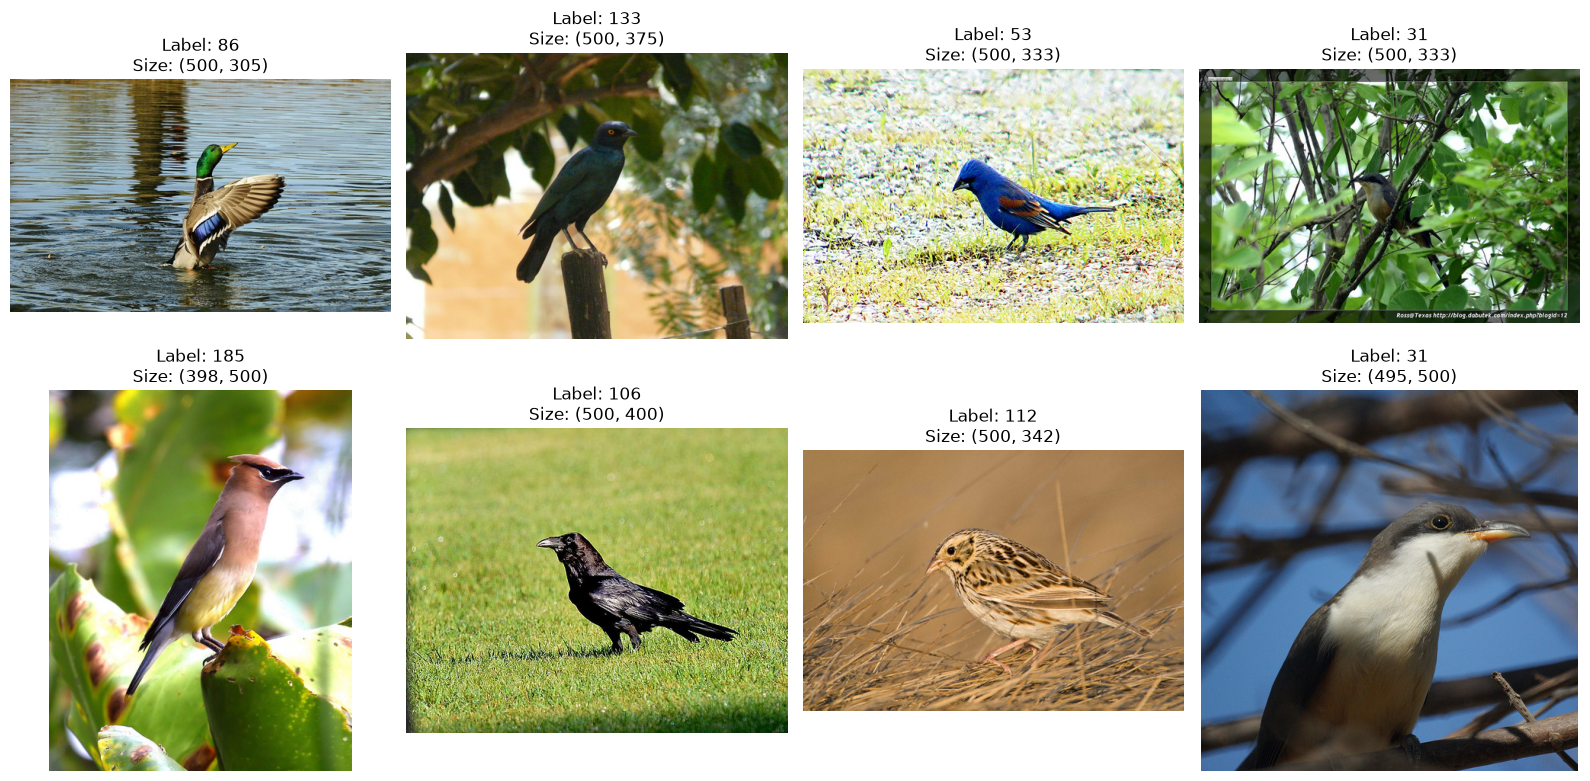

In [8]:
import random
import matplotlib.pyplot as plt

# Select 8 random training examples
random_indices = random.sample(range(len(train)), 8)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, idx in zip(axes, random_indices):
    example = train[idx]

    ax.imshow(example["image"])
    ax.set_title(
        f"Label: {example['label']}\n"
        f"Size: {example['image'].size}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# Inspect caption counts for the first 10 training examples
for i in range(10):
    example = train[i]
    captions = example["description"].splitlines()

    print(
        f"Image {i}: label={example['label']}, "
        f"captions={len(captions)}"
    )

Image 0: label=0, captions=10
Image 1: label=0, captions=10
Image 2: label=0, captions=10
Image 3: label=0, captions=10
Image 4: label=0, captions=10
Image 5: label=0, captions=10
Image 6: label=0, captions=10
Image 7: label=0, captions=10
Image 8: label=0, captions=10
Image 9: label=0, captions=10


In [10]:
from collections import Counter

caption_counts = Counter(
    len(example["description"].splitlines())
    for example in train
)

print("Caption count distribution:")
for count, images in sorted(caption_counts.items()):
    print(f"{count} captions: {images} images")

print("Total training images:", len(train))
print(
    "Total training captions:",
    sum(
        len(example["description"].splitlines())
        for example in train
    )
)

Caption count distribution:
10 captions: 5994 images
Total training images: 5994
Total training captions: 59940


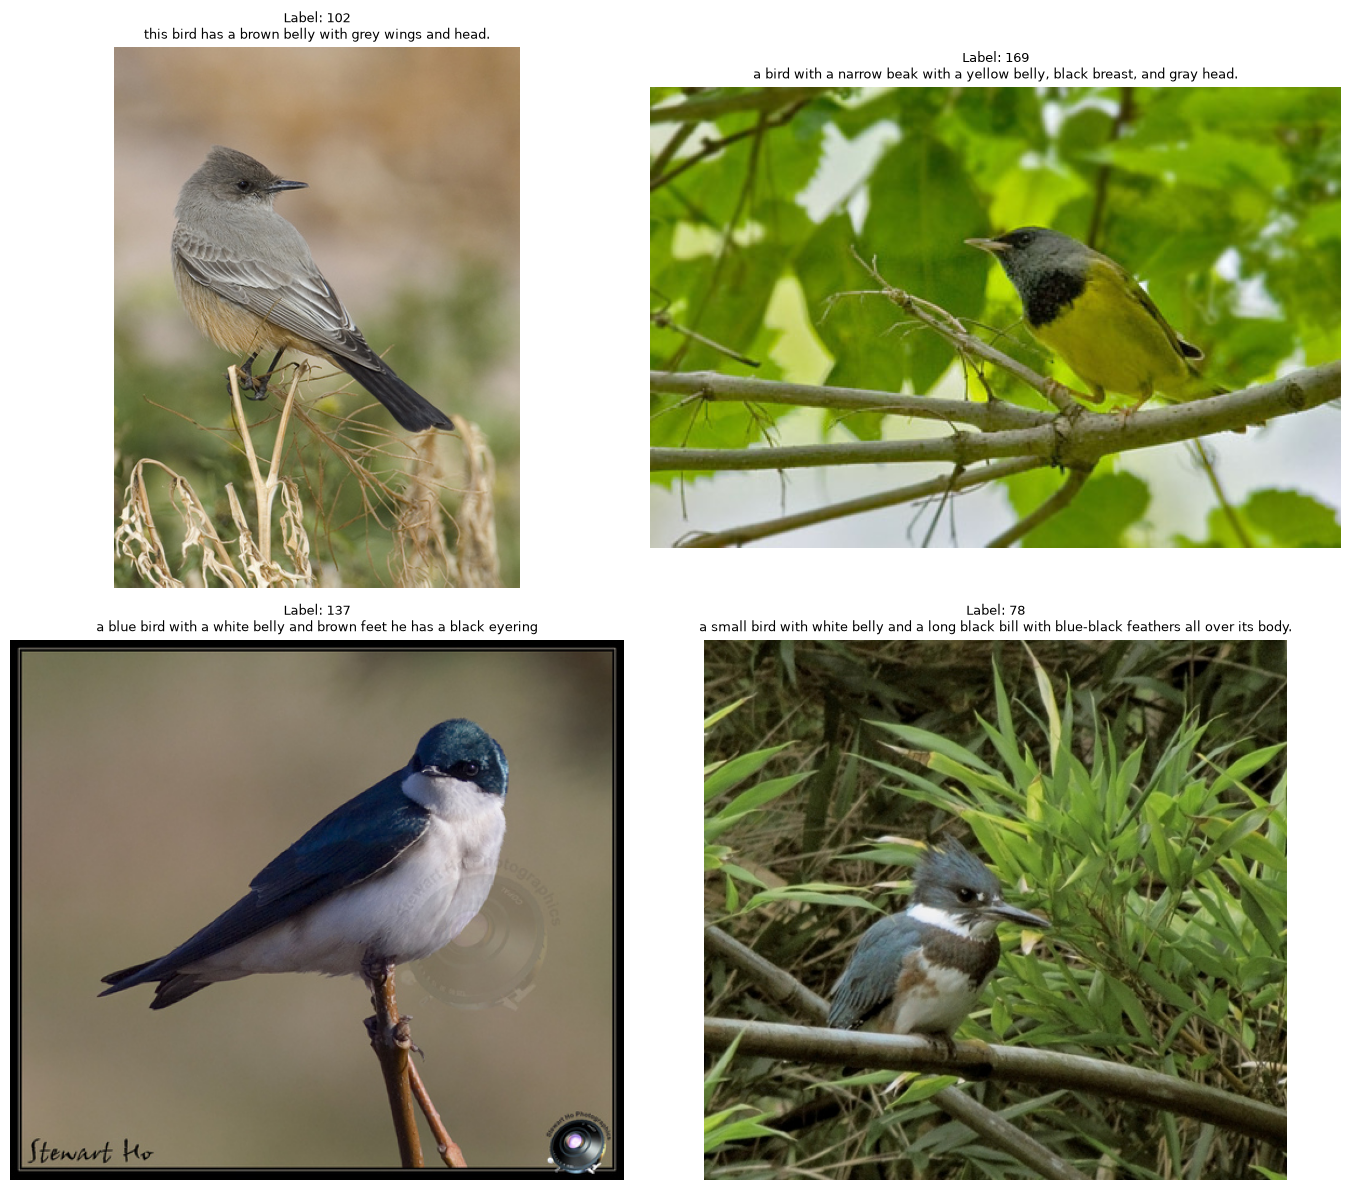

In [11]:
import random
import matplotlib.pyplot as plt

random_indices = random.sample(range(len(train)), 4)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, idx in zip(axes, random_indices):
    example = train[idx]

    ax.imshow(example["image"])
    ax.set_title(
        f"Label: {example['label']}\n"
        f"{example['description'].splitlines()[0]}",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
print("Dataset features:")
print(train.features)

print("\nFirst example:")
print(train[0])

Dataset features:
{'image': Image(mode=None, decode=True), 'description': Value('string'), 'label': ClassLabel(names=['Black footed Albatross', 'Laysan Albatross', 'Sooty Albatross', 'Groove billed Ani', 'Crested Auklet', 'Least Auklet', 'Parakeet Auklet', 'Rhinoceros Auklet', 'Brewer Blackbird', 'Red winged Blackbird', 'Rusty Blackbird', 'Yellow headed Blackbird', 'Bobolink', 'Indigo Bunting', 'Lazuli Bunting', 'Painted Bunting', 'Cardinal', 'Spotted Catbird', 'Gray Catbird', 'Yellow breasted Chat', 'Eastern Towhee', 'Chuck will Widow', 'Brandt Cormorant', 'Red faced Cormorant', 'Pelagic Cormorant', 'Bronzed Cowbird', 'Shiny Cowbird', 'Brown Creeper', 'American Crow', 'Fish Crow', 'Black billed Cuckoo', 'Mangrove Cuckoo', 'Yellow billed Cuckoo', 'Gray crowned Rosy Finch', 'Purple Finch', 'Northern Flicker', 'Acadian Flycatcher', 'Great Crested Flycatcher', 'Least Flycatcher', 'Olive sided Flycatcher', 'Scissor tailed Flycatcher', 'Vermilion Flycatcher', 'Yellow bellied Flycatcher', 'F

In [14]:
# Get the official species names from the dataset
class_names = train.features["label"].names

print("Number of species:", len(class_names))
print("\nFirst 10 species:")

for label, species in enumerate(class_names[:10]):
    print(f"Label {label}: {species}")

# Verify the first example
example = train[0]

print("\nFirst image label:", example["label"])
print("First image species:", class_names[example["label"]])
print("Image filename:", example["file_name"])

Number of species: 200

First 10 species:
Label 0: Black footed Albatross
Label 1: Laysan Albatross
Label 2: Sooty Albatross
Label 3: Groove billed Ani
Label 4: Crested Auklet
Label 5: Least Auklet
Label 6: Parakeet Auklet
Label 7: Rhinoceros Auklet
Label 8: Brewer Blackbird
Label 9: Red winged Blackbird

First image label: 0
First image species: Black footed Albatross
Image filename: Black_Footed_Albatross_0007_796138.jpg


In [15]:
from collections import Counter

# Get the official species names
train_class_names = train.features["label"].names
test_class_names = test.features["label"].names

# Count images per class in the test dataset
test_labels = Counter(example["label"] for example in test)

print("Training images:", len(train))
print("Test images:", len(test))

print("\nNumber of training classes:", len(train_class_names))
print("Number of test classes:", len(test_class_names))

print(
    "\nDo the class mappings match?",
    train_class_names == test_class_names
)

print("\nTest images per class:")
print("Minimum:", min(test_labels.values()))
print("Maximum:", max(test_labels.values()))
print("Average:", sum(test_labels.values()) / len(test_labels))

Training images: 5994
Test images: 5794

Number of training classes: 200
Number of test classes: 200

Do the class mappings match? True

Test images per class:
Minimum: 11
Maximum: 30
Average: 28.97


In [16]:
from collections import Counter

test_counts = Counter(example["label"] for example in test)
test_class_names = test.features["label"].names

# Show classes with fewer than 20 test images
for label in sorted(test_counts):
    if test_counts[label] < 20:
        print(
            f"Label {label}: "
            f"{test_class_names[label]} — "
            f"{test_counts[label]} images"
        )

Label 4: Crested Auklet — 14 images
Label 5: Least Auklet — 11 images
Label 7: Rhinoceros Auklet — 18 images
Label 17: Spotted Catbird — 15 images
Label 104: Whip poor Will — 19 images


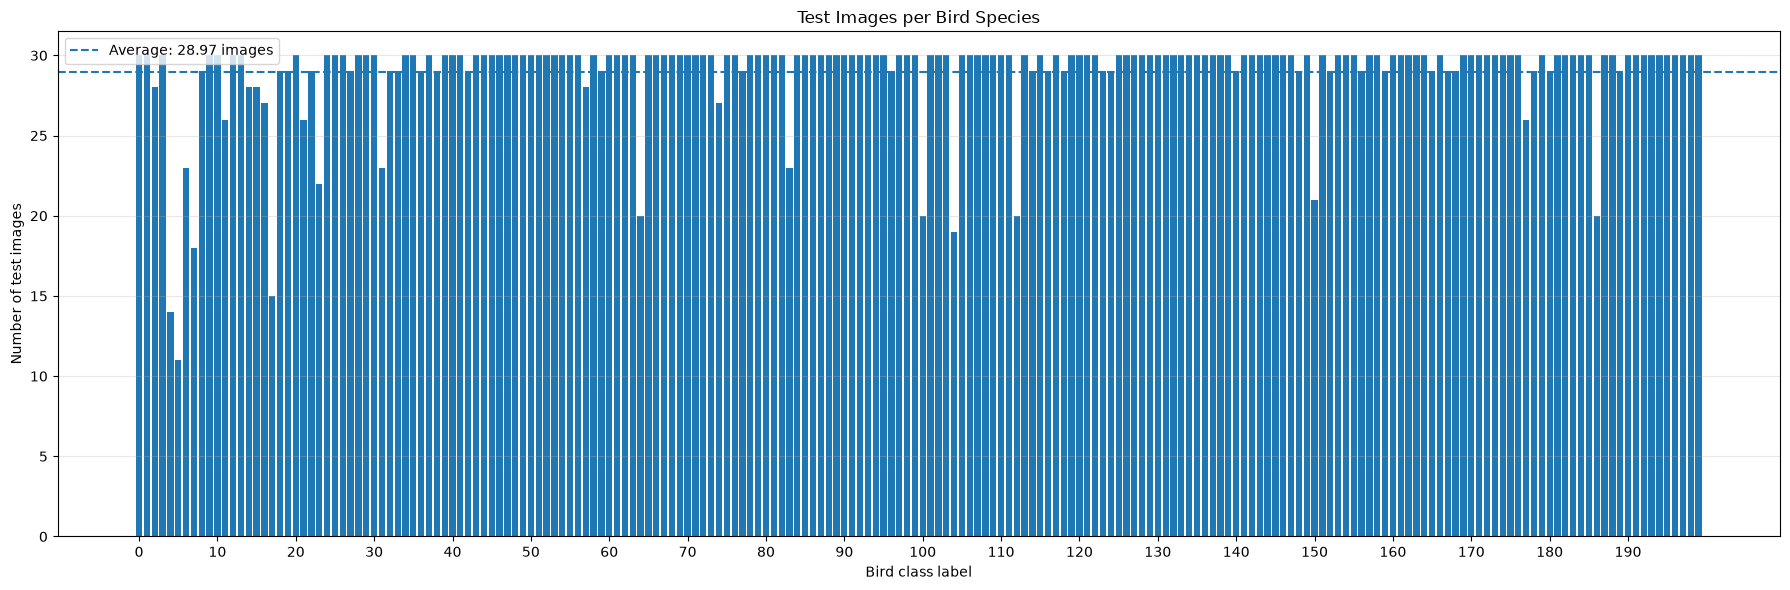

In [17]:
import matplotlib.pyplot as plt

# Count test images for every class in label order
test_counts_ordered = [
    test_counts[label]
    for label in range(len(test_class_names))
]

plt.figure(figsize=(18, 6))

plt.bar(range(200), test_counts_ordered)

plt.axhline(
    y=sum(test_counts_ordered) / len(test_counts_ordered),
    linestyle="--",
    label="Average: 28.97 images"
)

plt.xlabel("Bird class label")
plt.ylabel("Number of test images")
plt.title("Test Images per Bird Species")
plt.xticks(range(0, 200, 10))
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from collections import Counter

# Get the label of every training example
labels = [example["label"] for example in train]

# Split indices, keeping species proportions similar
train_indices, val_indices = train_test_split(
    range(len(train)),
    test_size=0.20,
    random_state=42,
    stratify=labels
)

# Get labels for each subset
train_labels = [labels[i] for i in train_indices]
val_labels = [labels[i] for i in val_indices]

print("Original training set:", len(train))
print("New training set:", len(train_indices))
print("Validation set:", len(val_indices))
print("Official test set:", len(test))

print("\nNumber of species in new training set:",
      len(set(train_labels)))
print("Number of species in validation set:",
      len(set(val_labels)))

print("\nTraining images per species:",
      min(Counter(train_labels).values()), "to",
      max(Counter(train_labels).values()))

print("Validation images per species:",
      min(Counter(val_labels).values()), "to",
      max(Counter(val_labels).values()))

Original training set: 5994
New training set: 4795
Validation set: 1199
Official test set: 5794

Number of species in new training set: 200
Number of species in validation set: 200

Training images per species: 23 to 24
Validation images per species: 5 to 6


In [19]:
import json
from pathlib import Path

split = {
    "train_indices": [int(i) for i in train_indices],
    "val_indices": [int(i) for i in val_indices],
    "random_state": 42,
    "train_fraction": 0.8,
    "dataset": "Multimodal-Fatima/CUB_train"
}

output_path = Path("../../outputs/eda/split_indices.json")
output_path.parent.mkdir(parents=True, exist_ok=True)

with output_path.open("w") as f:
    json.dump(split, f, indent=2)

print("Saved split to:", output_path.resolve())
print("Training indices:", len(split["train_indices"]))
print("Validation indices:", len(split["val_indices"]))

Saved split to: C:\Users\maria\OneDrive\Desktop\deep learning\From-Pixels-to-Language\outputs\eda\split_indices.json
Training indices: 4795
Validation indices: 1199


In [21]:
import sys
from pathlib import Path

project_root = Path.cwd()

# If the notebook is running from a subfolder, find the project root
while not (project_root / "src" / "data" / "transforms.py").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not find src/data/transforms.py")
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "src"))

print("Project root:", project_root)

Project root: c:\Users\maria\OneDrive\Desktop\deep learning\From-Pixels-to-Language


In [22]:
from data.transforms import get_image_transforms

print("Import successful!")

Import successful!


In [23]:

from datasets import load_dataset
from PIL import Image
from data.transforms import get_image_transforms

# Load one example from the training dataset
dataset = load_dataset("Multimodal-Fatima/CUB_train", split="train")

image = dataset[0]["image"]

# Apply our shared preprocessing
transform = get_image_transforms()
image_tensor = transform(image)

print("Original image size:", image.size)
print("Transformed tensor shape:", image_tensor.shape)
print("Minimum pixel value:", image_tensor.min().item())
print("Maximum pixel value:", image_tensor.max().item())


Original image size: (500, 301)
Transformed tensor shape: torch.Size([3, 224, 224])
Minimum pixel value: 0.09019608050584793
Maximum pixel value: 1.0


In [24]:
import json

split_path = project_root / "outputs" / "eda" / "split_indices.json"

with open(split_path, "r") as f:
    split = json.load(f)

train_indices = split["train_indices"]
val_indices = split["val_indices"]

print("Training examples:", len(train_indices))
print("Validation examples:", len(val_indices))
print("Total:", len(train_indices) + len(val_indices))
print("Overlap:", len(set(train_indices) & set(val_indices)))

Training examples: 4795
Validation examples: 1199
Total: 5994
Overlap: 0


In [25]:

from data.dataset import CUBDataset
from data.transforms import get_image_transforms

transform = get_image_transforms()

train_data = CUBDataset(
    huggingface_dataset=dataset,
    indices=train_indices,
    transform=transform,
)

sample = train_data[0]

print("Image shape:", sample["image"].shape)
print("Label:", sample["label"].item())
print("Number of captions:", len(sample["captions"]))
print("First caption:", sample["captions"][0])


Image shape: torch.Size([3, 224, 224])
Label: 61
Number of captions: 10
First caption: this bird has a white belly and breast with gray wings and tail.


In [28]:
from torch.utils.data import DataLoader
import torch


def collate_fn(batch):
    images = torch.stack([item["image"] for item in batch])
    labels = torch.stack([item["label"] for item in batch])
    captions = [item["captions"] for item in batch]

    return {
        "image": images,
        "label": labels,
        "captions": captions,
    }


batch_size = 32

# Create the training dataset
train_data = CUBDataset(
    huggingface_dataset=dataset,
    indices=train_indices,
    transform=get_image_transforms(),
)

# Create the validation dataset
val_data = CUBDataset(
    huggingface_dataset=dataset,
    indices=val_indices,
    transform=get_image_transforms(),
)

# Create the DataLoaders
train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 150
Validation batches: 38


In [29]:
batch = next(iter(train_loader))

print("Images shape:", batch["image"].shape)
print("Labels shape:", batch["label"].shape)
print("Number of caption lists:", len(batch["captions"]))
print("Captions for first image:", len(batch["captions"][0]))
print("First label:", batch["label"][0].item())

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Number of caption lists: 32
Captions for first image: 10
First label: 20


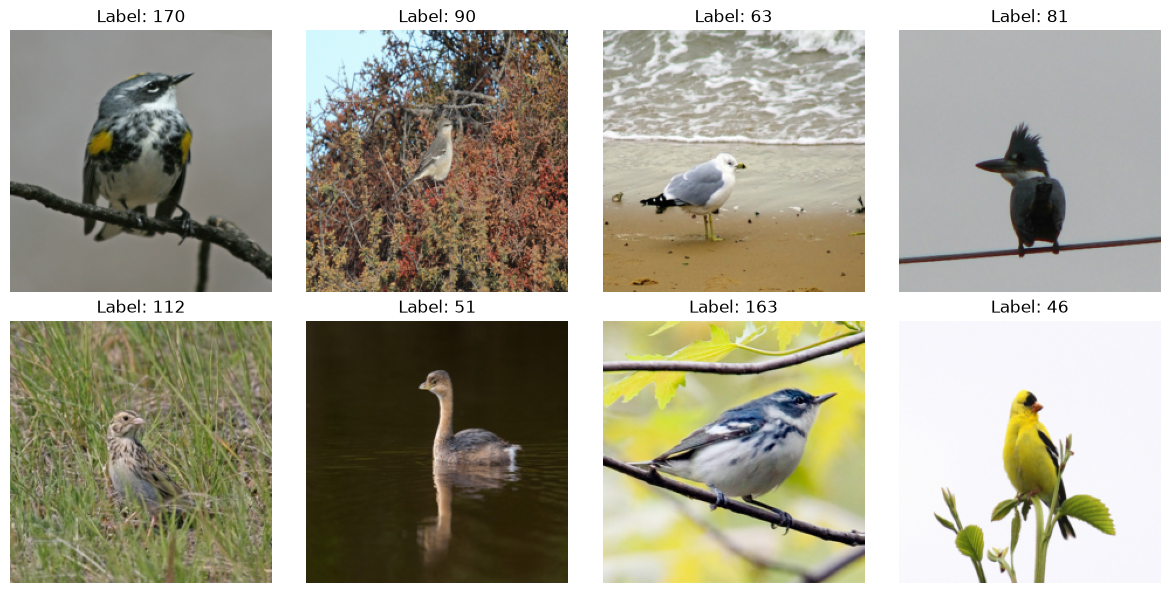

In [30]:
import matplotlib.pyplot as plt

batch = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image = batch["image"][i].permute(1, 2, 0).numpy()
    label = batch["label"][i].item()

    ax.imshow(image)
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [31]:
# Get one batch from the training DataLoader
batch = next(iter(train_loader))

# Check image tensors
assert batch["image"].shape[1:] == (3, 224, 224)
assert batch["image"].dtype == torch.float32

# Check labels
assert batch["label"].dtype == torch.long
assert batch["label"].shape[0] == batch["image"].shape[0]

# Check captions
assert len(batch["captions"]) == batch["image"].shape[0]
assert all(len(captions) == 10 for captions in batch["captions"])

# Check pixel values
assert batch["image"].min() >= 0
assert batch["image"].max() <= 1

print("All batch checks passed!")

All batch checks passed!


In [32]:
# Get the final batch from the training DataLoader
last_batch = list(train_loader)[-1]

print("Number of training examples:", len(train_data))
print("Batch size:", batch_size)
print("Number of batches:", len(train_loader))
print("Images in the last batch:", last_batch["image"].shape[0])
print("Labels in the last batch:", last_batch["label"].shape[0])

Number of training examples: 4795
Batch size: 32
Number of batches: 150
Images in the last batch: 27
Labels in the last batch: 27


In [33]:
from pathlib import Path

data_folder = project_root / "src" / "data"

for file in sorted(data_folder.iterdir()):
    print(file.name)

01_dataset_inspection.ipynb
__pycache__
dataset.py
transforms.py
